# Embedding Quality EDA - ItemDNN + HSTU (Stage 1)

This notebook audits the **item-side** embeddings exported by `train_item_embedding_cli.py` (`export_catalog_embeddings`) into `item_embeddings.parquet` (columns `item_id` int64 and `embedding` FixedSizeList<float32>[256]).

**What the embeddings are.** `ItemDNN` consumes `[mm_emb (1024-d, zero-filled when absent), has_mm flag, 13 categorical embeddings]`, runs `MLP(512, 256) -> 256-d`, then `F.normalize(p=2)`. Training is InfoNCE at `temperature=0.05` with in-batch negatives plus a `log_q` popularity correction, and the positive for each user vector is the target item embedding. So the catalog geometry examined here is exactly what item-to-item retrieval and the InfoNCE denominator see.

**What this notebook can and cannot tell you.** It can audit catalog geometry: unit norm, dead dimensions, cone collapse, effective rank, anisotropy, nearest-neighbour margin, hubness, duplicates, and (optionally) signal retention vs `mm_emb`, agreement with observed co-occurrence, item_id leakage, cluster structure. It cannot recompute the training val metrics (`recall@10`, `recall@5`, `mrr`, `cosine_gap`) because those need the HSTU user encoder, which the export does not contain - read them from TensorBoard / the training log (`val/recall@10`, `val/mrr`, `val/cosine_gap`).

**Sections.** Cells 1-6 need only the parquet and always run. Cells 7-10 are optional and skip themselves cleanly when the referenced file or scikit-learn is absent. No package is installed by this notebook.

**Checklist:** unit norms -> dead dims -> cone collapse -> effective rank -> anisotropy / uniformity -> NN margin -> hubness -> duplicates -> (optional) mm_emb retention -> (optional) co-occurrence -> (optional) item_id leakage -> (optional) clusters -> scorecard.

In [1]:
# ==========================================
# Standalone Embedding Loading & Normalization
# ==========================================
import pyarrow.dataset as ds
import numpy as np
import pandas as pd

# Configuration
PARQUET_PATH = "./local/2026-13-10-1-ei/item_embeddings.parquet"
SAMPLE_SIZE = 50_000  # Adjust as needed (e.g., 50k-100k is ideal for EDA)
RANDOM_SEED = 42

# Reproducible random generator
rng = np.random.default_rng(RANDOM_SEED)

# 1. Load dataset metadata & sample indices
dataset = ds.dataset(PARQUET_PATH, format="parquet")
total_rows = dataset.count_rows()
sample_size = min(SAMPLE_SIZE, total_rows)

sampled_indices = rng.choice(
    total_rows,
    size=sample_size,
    replace=False,
)
sampled_indices.sort()

# 2. Extract sampled rows
table = dataset.take(sampled_indices)
item_ids = table.column("item_id").to_numpy()
embeddings_matrix = np.vstack(
    table.column("embedding").to_pylist()
).astype(np.float32)

# 3. Create clean indexed DataFrame
embeddings_df = pd.DataFrame(
    embeddings_matrix,
    index=pd.Index(item_ids, name="item_id"),
)

assert embeddings_df.index.is_unique, "Embedding item_ids must be unique."

# 4. L2 Normalize once for efficient cosine distance / similarity checks
embedding_norms = np.linalg.norm(
    embeddings_matrix, axis=1, keepdims=True
)

if np.any(embedding_norms < 1e-12):
    raise ValueError("Zero-norm embeddings found in the sample.")

norm_embeddings = embeddings_matrix / embedding_norms

print(f"Total parquet rows: {total_rows:,}")
print(f"Sampled items: {len(embeddings_df):,}")
print(f"Embedding shape: {embeddings_matrix.shape}")
print(f"Random seed: {RANDOM_SEED}")

Total parquet rows: 4,783,154
Sampled items: 50,000
Embedding shape: (50000, 256)
Random seed: 42


## 0. Setup - plotting, RNG, and memory-bounded helpers

50k x 256 is small, but the full pairwise similarity matrix (50k^2 = 2.5e9 values) would be ~10 GB in float32. Every pairwise operation below is therefore either row-blocked or subsampled. Only numpy / pandas / matplotlib are required; scikit-learn is used by one optional section if it happens to be installed.

In [ ]:
# ==========================================
# Setup: plotting, RNG, memory-bounded helpers
# ==========================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda v: f'{v:0.4f}')
plt.rcParams.update({'figure.dpi': 110, 'figure.figsize': (9, 4), 'axes.grid': True,
                     'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

RNG = np.random.default_rng(RANDOM_SEED)   # RANDOM_SEED comes from the loading cell
N, DIM = norm_embeddings.shape

# Sampling budgets. Raise them for more precision, lower them for speed.
SIM_SAMPLE = min(N, 20_000)     # query rows used for pairwise / kNN statistics
N_RANDOM_PAIRS = 1_000_000      # random pairs for uniformity + anisotropy
K_NN = 20                       # neighbours kept per query
HUB_QUERIES = min(N, 10_000)    # query subsample for hubness (k-occurrence)
CHUNK = 1024                    # row block for blocked matmuls (~CHUNK * N floats)

QUALITY = {}                    # every section records its headline numbers here

def l2(x, axis=-1):
    return x / np.clip(np.linalg.norm(x, axis=axis, keepdims=True), 1e-12, None)

def iter_sim_blocks(A, B, block=CHUNK):
    # Row-blocked A @ B.T keeps peak memory at ~ block * len(B) float32 values.
    for start in range(0, A.shape[0], block):
        stop = min(start + block, A.shape[0])
        yield start, stop, np.asarray(A[start:stop] @ B.T, dtype=np.float32)

def topk_within_catalog(Q, catalog, k=K_NN, block=CHUNK, self_idx=None):
    # Exact cosine top-k of every query row inside the catalog (brute force, blocked).
    sims_out = np.full((Q.shape[0], k), -np.inf, dtype=np.float32)
    idx_out = np.full((Q.shape[0], k), -1, dtype=np.int64)
    cat_idx = np.arange(catalog.shape[0], dtype=np.int64)
    for start, stop, sims in iter_sim_blocks(Q, catalog, block):
        if self_idx is not None:
            sims[np.arange(stop - start), self_idx[start:stop]] = -np.inf   # drop the self-match
        cand_sim = np.concatenate([sims_out[start:stop], sims], axis=1)
        cand_idx = np.concatenate([idx_out[start:stop],
                                   np.broadcast_to(cat_idx, (stop - start, catalog.shape[0]))], axis=1)
        part = np.argpartition(-cand_sim, kth=k - 1, axis=1)[:, :k]
        sel_sim = np.take_along_axis(cand_sim, part, axis=1)
        sel_idx = np.take_along_axis(cand_idx, part, axis=1)
        order = np.argsort(-sel_sim, axis=1)
        sims_out[start:stop] = np.take_along_axis(sel_sim, order, axis=1)
        idx_out[start:stop] = np.take_along_axis(sel_idx, order, axis=1)
    return sims_out, idx_out

def pca_numpy(X, n_components=64):
    # PCA via SVD so scikit-learn is not required. Returns (mean, components, singvals, evr).
    mu = X.mean(axis=0)
    _, S, Vt = np.linalg.svd(X - mu, full_matrices=False)
    var = S ** 2
    return mu, Vt[:n_components], S, var / var.sum()

def linear_cka(X, Y):
    # Linear CKA (centered HSIC): how much two representation spaces share, scale-free.
    X = X - X.mean(axis=0)
    Y = Y - Y.mean(axis=0)
    xty = np.linalg.norm(X.T @ Y) ** 2
    xtx = np.linalg.norm(X.T @ X)
    yty = np.linalg.norm(Y.T @ Y)
    return float(xty / (xtx * yty + 1e-12))

def half_half_ks(sample):
    # Split-half KS distance: is the measured distribution stable at this sample size?
    s = np.sort(np.asarray(sample))
    n = s.size // 2
    a, b = s[:n], s[n:2 * n]
    grid = np.union1d(a, b)
    ks_diffs = np.abs(np.searchsorted(a, grid, side='right') / a.size -
                      np.searchsorted(b, grid, side='right') / b.size)
    return float(ks_diffs.max())

print(f'Embeddings ready: N={N:,}  dim={DIM}  seed={RANDOM_SEED}')
print(f'Budgets: SIM_SAMPLE={SIM_SAMPLE:,}  N_RANDOM_PAIRS={N_RANDOM_PAIRS:,}  K_NN={K_NN}  HUB_QUERIES={HUB_QUERIES:,}  CHUNK={CHUNK}')

Embeddings ready: N=50,000  dim=256  seed=42
Budgets: SIM_SAMPLE=20,000  N_RANDOM_PAIRS=1,000,000  K_NN=20  HUB_QUERIES=10,000  CHUNK=1024


## 1. Sanity and health

`ItemDNN.forward` ends in `F.normalize(p=2)` and the export re-casts to float32, so **every norm should be ~1.0** and every dimension should be finite. Three failure modes worth catching here:

- **Norms far from 1** -> broken/partial export or post-processing that skipped normalization.
- **Dead dimensions** (std < 1e-3) -> the MLP is not using its capacity; the effective embedding is smaller than 256-d.
- **Cone collapse** -> items crowd into a narrow cone around the global mean instead of spreading over the sphere. Measured as `cos(item, global mean direction)`; ~0 is well spread, >~0.7 means everything looks alike, which in InfoNCE terms means all negatives become hard-but-uninformative.

Raw norm min/median/max : 1.00000 / 1.00000 / 1.00000
Non-finite entries      : 0
Rows with norm < 1e-6   : 0
Rows with |norm - 1| > 1e-3 : 0
Duplicate item_ids      : 0
Dead dims (std < 1e-3)  : 0/256   (want ~0)


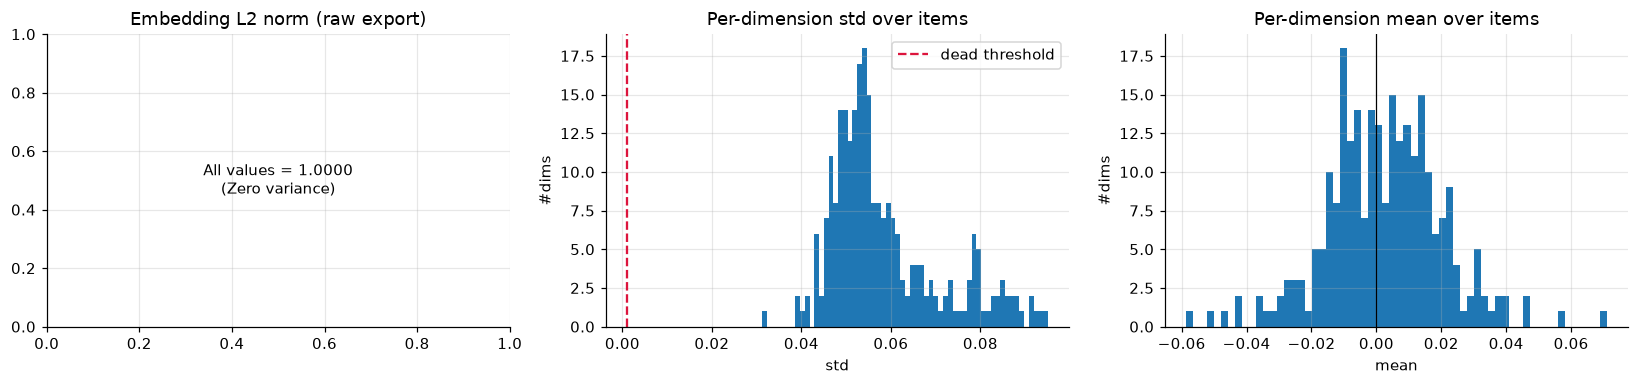

cos(item, global mean dir): mean 0.291  p10 0.037  p90 0.538  max 0.847
Interpretation: near 0 = well spread over the sphere, >~0.7 = narrow cone (weak separation).


In [5]:
# ==========================================
# 1. Sanity: finiteness, unit norm, dead dimensions, cone collapse
# ==========================================
raw_norms = np.linalg.norm(embeddings_matrix, axis=1)
print('Raw norm min/median/max : %.5f / %.5f / %.5f' % (raw_norms.min(), np.median(raw_norms), raw_norms.max()))
print('Non-finite entries      :', int((~np.isfinite(embeddings_matrix)).sum()))
print('Rows with norm < 1e-6   :', int((raw_norms < 1e-6).sum()))
print('Rows with |norm - 1| > 1e-3 :', int((np.abs(raw_norms - 1.0) > 1e-3).sum()))
print('Duplicate item_ids      :', int(N - embeddings_df.index.nunique()))

QUALITY['norm_dev_p99'] = float(np.percentile(np.abs(raw_norms - 1.0), 99))

# Per-dimension spread. A near-constant dimension carries no information.
dim_std = norm_embeddings.std(axis=0)
dim_mean = norm_embeddings.mean(axis=0)
dead_dims = int((dim_std < 1e-3).sum())
QUALITY['dead_dims'] = dead_dims
print(f'Dead dims (std < 1e-3)  : {dead_dims}/{DIM}   (want ~0)')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))

plots_data = [
    (raw_norms, 'Embedding L2 norm (raw export)', '||e||_2', '#items'),
    (dim_std, 'Per-dimension std over items', 'std', '#dims'),
    (dim_mean, 'Per-dimension mean over items', 'mean', '#dims')
]

for i, (data, title, xlabel, ylabel) in enumerate(plots_data):
    if np.isclose(data.min(), data.max()):
        ax[i].text(0.5, 0.5, f'All values = {data.min():.4f}\n(Zero variance)', 
                   ha='center', va='center', transform=ax[i].transAxes)
        ax[i].set(title=title)
    else:
        ax[i].hist(data, bins=60)
        ax[i].set(title=title, xlabel=xlabel, ylabel=ylabel)
        if i == 1:
            ax[i].axvline(1e-3, color='crimson', ls='--', label='dead threshold')
            ax[i].legend()
        elif i == 2:
            ax[i].axvline(0.0, color='k', lw=0.8)

plt.tight_layout()
plt.show()

# Cone collapse: cosine of each item to the global mean direction.
mean_dir = l2(dim_mean[None, :])[0]
cos_to_mean = norm_embeddings @ mean_dir
QUALITY['mean_cos_to_centroid'] = float(cos_to_mean.mean())
print('cos(item, global mean dir): mean %.3f  p10 %.3f  p90 %.3f  max %.3f' % (
    cos_to_mean.mean(), np.percentile(cos_to_mean, 10), np.percentile(cos_to_mean, 90), cos_to_mean.max()))
print('Interpretation: near 0 = well spread over the sphere, >~0.7 = narrow cone (weak separation).')

## 2. Effective dimensionality (dimensional collapse)

Contrastive objectives with a small temperature and in-batch negatives are known to push embeddings into a low-rank subspace even when the output layer has 256 units. Two robust summaries (both scale-free):

- **Effective rank** = `exp(entropy of normalized eigenvalues)`. Caps at 256 for isotropic Gaussian noise; a healthy 256-d contrastive space typically lands in the tens-to-low-hundreds.
- **Participation ratio** = `(sum lambda)^2 / sum lambda^2`, which weights the large components more heavily.

If only ~10-30 dims carry everything, ANN recall and downstream ranking are limited by rank, not by the model width.

Effective rank (exp entropy)  : 24.8   (upper bound 256; want >= ~32)
Participation ratio           : 16.8
Dims for 90% / 99% of variance: 23 / 51
Top-10 explained variance ratio: [0.1265 0.1129 0.0822 0.0801 0.066  0.0457 0.0425 0.0385 0.0336 0.0314]


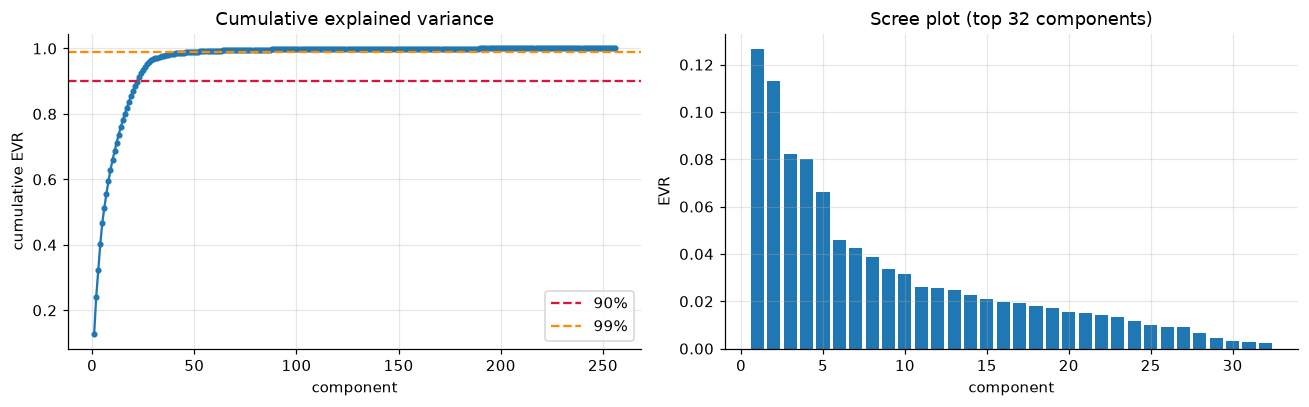

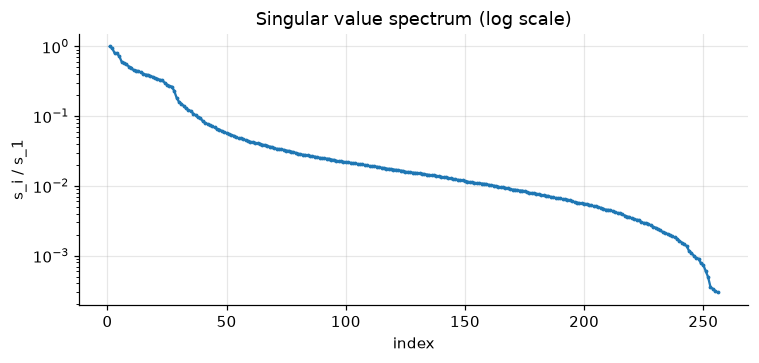

In [6]:
# ==========================================
# 2. Effective dimensionality (dimensional collapse)
# ==========================================
mu, V, S, evr = pca_numpy(norm_embeddings, n_components=64)
var = S ** 2
p = var / var.sum()
eff_rank = float(np.exp(-(p * np.log(p + 1e-12)).sum()))      # entropy-based effective rank
part_ratio = float(var.sum() ** 2 / (var ** 2).sum())          # participation ratio
dims_for_90 = int(np.searchsorted(np.cumsum(evr), 0.90) + 1)
dims_for_99 = int(np.searchsorted(np.cumsum(evr), 0.99) + 1)
QUALITY.update(eff_rank=eff_rank, part_ratio=part_ratio, dims_for_90_var=dims_for_90)

print(f'Effective rank (exp entropy)  : {eff_rank:.1f}   (upper bound {min(N, DIM)}; want >= ~{min(N, DIM) // 8})')
print(f'Participation ratio           : {part_ratio:.1f}')
print(f'Dims for 90% / 99% of variance: {dims_for_90} / {dims_for_99}')
print('Top-10 explained variance ratio:', np.round(evr[:10], 4))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(np.arange(1, len(evr) + 1), np.cumsum(evr), marker='o', ms=3)
ax[0].axhline(0.90, color='crimson', ls='--', label='90%')
ax[0].axhline(0.99, color='darkorange', ls='--', label='99%')
ax[0].set(title='Cumulative explained variance', xlabel='component', ylabel='cumulative EVR')
ax[0].legend()
ax[1].bar(np.arange(1, 33), evr[:32])
ax[1].set(title='Scree plot (top 32 components)', xlabel='component', ylabel='EVR')
plt.tight_layout()
plt.show()

# The singular value spectrum shows the shape of the tail: flat = all dims used.
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.semilogy(np.arange(1, S.size + 1), S / S[0], marker='.', ms=3)
ax.set(title='Singular value spectrum (log scale)', xlabel='index', ylabel='s_i / s_1')
plt.tight_layout()
plt.show()

## 3. Anisotropy, uniformity, and the random-pair baseline

Every retrieval claim is relative: an item embedding is only useful if `cos(related pair)` beats `cos(random pair)`. So first measure the **random-pair baseline**.

- **Anisotropy** = mean cosine over random pairs. ~0 means isotropic on the sphere; large positive values (typical for language-style embeddings, and a known risk with small temperature) mean a shared direction dominates and every pair looks similar.
- **Uniformity** (Wang & Isola 2020) = `log E[exp(-2 ||xi - xj||^2)]` over random pairs. More negative = better spread. On a 256-d unit sphere a well-spread space sits roughly in [-4, -2]; values above ~-1 indicate crowding.
- **Split-half KS** answers a methodological question: with this many sampled pairs, is the estimate stable, or is the number an artifact of the sample?

Random pairs          : 999,984
Random-pair cosine    : mean +0.0843  std 0.2372  p0.1 -0.540  p99.9 +0.823  max +0.983
Anisotropy (mean cos) : +0.0843   (want |value| small; >0.3 = dominant shared direction)
Uniformity            : -3.1891   (more negative = better spread)
Split-half KS distance: 1.0000   (near 0 = the estimate is stable at this sample size)


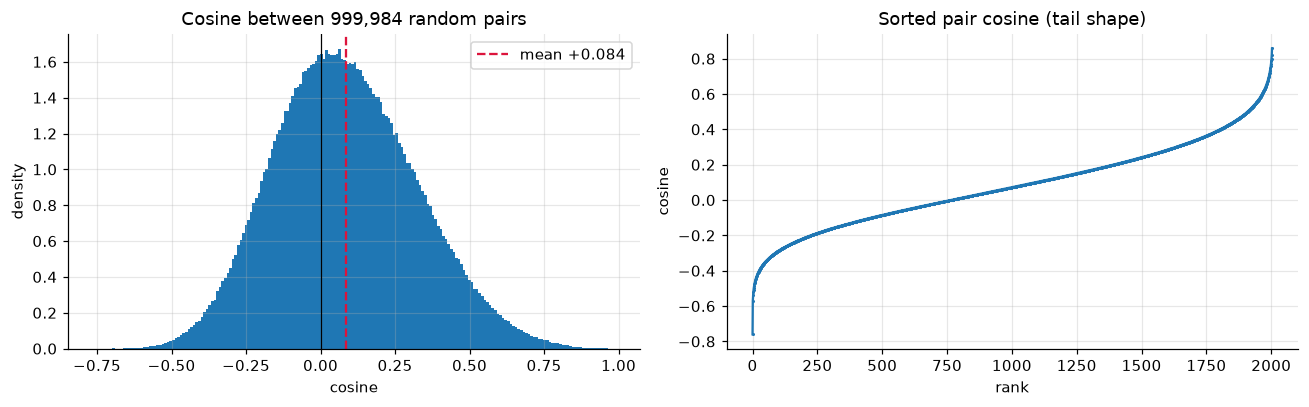

Pairs with cosine >  0.5: 4.772%
Pairs with cosine >  0.8: 0.151%
Pairs with cosine > 0.95: 0.003%


In [ ]:
# ==========================================
# 3. How similar are two random items? (anisotropy / uniformity)
# ==========================================
idx_a = RNG.integers(0, N, N_RANDOM_PAIRS)
idx_b = RNG.integers(0, N, N_RANDOM_PAIRS)
keep = idx_a != idx_b
A_rand, B_rand = norm_embeddings[idx_a[keep]], norm_embeddings[idx_b[keep]]
pair_cos = np.einsum('ij,ij->i', A_rand, B_rand)
sq_dist = np.maximum(2.0 - 2.0 * pair_cos, 0.0)
uniformity = float(np.log(np.exp(-2.0 * sq_dist).mean()))
anisotropy = float(pair_cos.mean())
sim_consistency = half_half_ks(pair_cos)

QUALITY.update(uniformity=uniformity, random_pair_cos_mean=anisotropy,
               pair_sim_split_half_ks=sim_consistency)

print(f'Random pairs          : {keep.sum():,}')
print(f'Random-pair cosine    : mean {pair_cos.mean():+.4f}  std {pair_cos.std():.4f}  ' +
      f'p0.1 {np.percentile(pair_cos, 0.1):+.3f}  p99.9 {np.percentile(pair_cos, 99.9):+.3f}  max {pair_cos.max():+.3f}')
print(f'Anisotropy (mean cos) : {anisotropy:+.4f}   (want |value| small; >0.3 = dominant shared direction)')
print(f'Uniformity            : {uniformity:+.4f}   (more negative = better spread)')
print(f'Split-half KS distance: {sim_consistency:.4f}   (near 0 = the estimate is stable at this sample size)')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(pair_cos, bins=200, density=True)
ax[0].axvline(0.0, color='k', lw=0.8)
ax[0].axvline(pair_cos.mean(), color='crimson', ls='--', label=f'mean {pair_cos.mean():+.3f}')
ax[0].set(title=f'Cosine between {keep.sum():,} random pairs', xlabel='cosine', ylabel='density')
ax[0].legend()
ax[1].plot(np.sort(pair_cos)[::max(1, pair_cos.size // 2000)], marker='.', ms=2)
ax[1].set(title='Sorted pair cosine (tail shape)', xlabel='rank', ylabel='cosine')
plt.tight_layout()
plt.show()

# How much of the sphere is actually reachable? Fraction of pairs above thresholds.
for thr in [0.5, 0.8, 0.95]:
    print(f'Pairs with cosine > {thr:>4}: {(pair_cos > thr).mean():.3%}')

## 4. Local neighbourhood structure (the actual retrieval signal)

This mirrors the geometry behind the training val metrics (`pos_cosine`, `neg_cosine`, `cosine_gap` in `train_item_embedding_cli.py`), but over the exported catalog only, using the same brute-force cosine top-k that `faiss.IndexFlatIP` uses.

Judged here:
- **1-NN cosine** should be clearly above the random-pair baseline. A tiny gap means the space is nearly unstructured.
- **Decay by rank**: if cos(rank 1) is close to cos(rank 20), local structure is weak and top-k lists are near-arbitrary.
- **Isolated items**: queries whose best neighbour is still far from them will never be retrieved reliably.

Query items                     : 20,000
cos to 1st neighbour            : mean 0.9290  p10 0.8721  min 0.7089
cos to neighbours 1..20          : mean 0.8645
cos to a random item            : mean +0.0839  std 0.2377
Retrieval margin (NN1 - random) : +0.8450   (0 = no structure, ~1 = strong margin)
Items whose 1-NN cosine < 0.5   : 0.00%   (noisy / isolated embeddings)


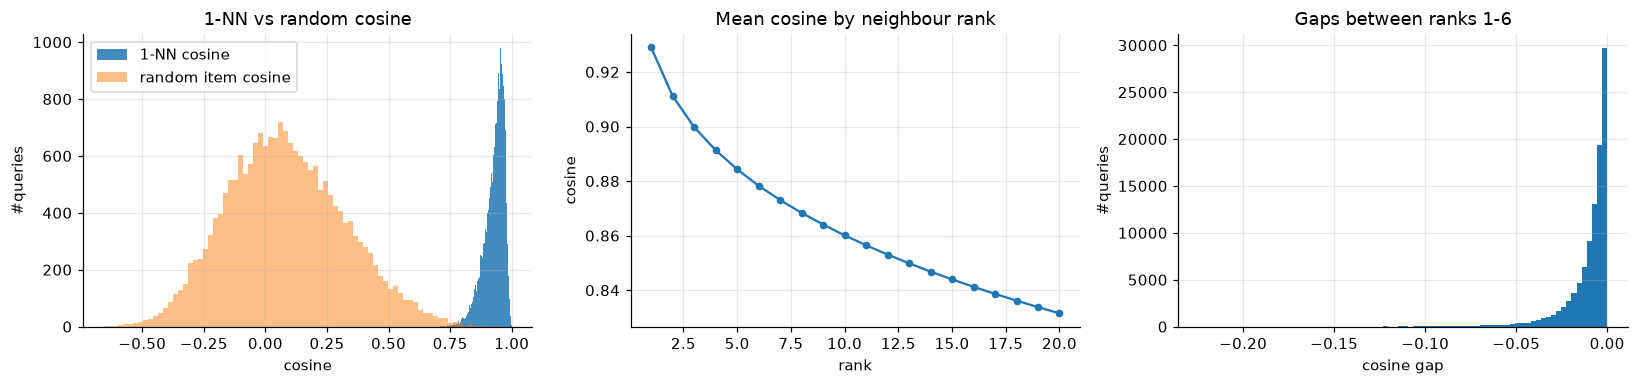

1-NN cosine quantiles p1/p10/p50/p90/p99: [0.802  0.8721 0.9384 0.9725 0.9875]


In [9]:
# ==========================================
# 4. Local neighbourhood structure (1-NN vs random)
# ==========================================
q_idx = RNG.choice(N, size=SIM_SAMPLE, replace=False)
q_idx.sort()
Q = norm_embeddings[q_idx]

nn_sim, nn_idx = topk_within_catalog(Q, norm_embeddings, k=K_NN, self_idx=q_idx)
nn1 = nn_sim[:, 0]

partner = RNG.integers(0, N, q_idx.size)
ok = partner != q_idx
rand_sim = np.einsum('ij,ij->i', Q[ok], norm_embeddings[partner[ok]])

margin = float(nn1.mean() - rand_sim.mean())
QUALITY.update(nn1_cos_mean=float(nn1.mean()), nn1_cos_p10=float(np.percentile(nn1, 10)),
               nn1_rand_gap=margin, nnk_cos_mean=float(nn_sim.mean()),
               pct_items_isolated=float((nn1 < 0.5).mean()))

print(f'Query items                     : {q_idx.size:,}')
print(f'cos to 1st neighbour            : mean {nn1.mean():.4f}  p10 {np.percentile(nn1, 10):.4f}  min {nn1.min():.4f}')
print(f'cos to neighbours 1..{K_NN:<2}          : mean {nn_sim.mean():.4f}')
print(f'cos to a random item            : mean {rand_sim.mean():+.4f}  std {rand_sim.std():.4f}')
print(f'Retrieval margin (NN1 - random) : {margin:+.4f}   (0 = no structure, ~1 = strong margin)')
print(f'Items whose 1-NN cosine < 0.5   : {(nn1 < 0.5).mean():.2%}   (noisy / isolated embeddings)')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(nn1, bins=80, alpha=0.85, label='1-NN cosine')
ax[0].hist(rand_sim, bins=80, alpha=0.5, label='random item cosine')
ax[0].set(title='1-NN vs random cosine', xlabel='cosine', ylabel='#queries')
ax[0].legend()
ax[1].plot(np.arange(1, K_NN + 1), nn_sim.mean(0), marker='o', ms=4)
ax[1].set(title='Mean cosine by neighbour rank', xlabel='rank', ylabel='cosine')
ax[2].hist(np.diff(nn_sim[:, :6], axis=1).ravel(), bins=80)
ax[2].set(title='Gaps between ranks 1-6', xlabel='cosine gap', ylabel='#queries')
plt.tight_layout()
plt.show()

# Shape check: a healthy space has a heavy left tail on 1-NN similarity (some items are
# unambiguous) and a thin one on the high end (nobody has 20 identical twins).
print('1-NN cosine quantiles p1/p10/p50/p90/p99:', np.round(np.percentile(nn1, [1, 10, 50, 90, 99]), 4))

## 5. Hubness (popularity concentration)

With InfoNCE and in-batch negatives, items that appear as negatives often (i.e. popular items) can become **hubs**: they end up in a disproportionate share of every query's top-K. This is a classic failure of cosine geometry + contrastive training and it directly hurts ANN diversity and skewed recommendations.

`N_k` = number of queries (out of the query subsample) that have item k in their top-K. Uniform geometry gives every item roughly the same `N_k`; hubs give a long tail. Reported as:
- the share of items that are **never** retrieved,
- **Gini** of `N_k` (0 = perfectly uniform, 1 = one item takes everything),
- share of neighbour slots held by the **top 1%** of items,
- the identity of the biggest hubs by `item_id` (cross-check against item popularity offline).

Queries x K            : 10,000 x 20 = 200,000 neighbour slots over 50,000 items
Expected slots per item: 4.00
Distinct items retrieved: 46,910 / 50,000
Never-retrieved items   : 6.18%
N_k entropy / max       : 10.576 / 10.820   (closer to max = more uniform)
Gini of N_k             : -0.3737   (0 = uniform, 1 = single hub)
Top 1% items hold       : 3.46% of all neighbour slots   (uniform would be ~1%)
Top 10 hub item_ids     : [3027094, 4722878, 4084437, 3098379, 61015, 1472862, 2064144, 3145286, 4647625, 842538]
Their N_k               : [27, 25, 25, 22, 22, 21, 20, 19, 19, 19]


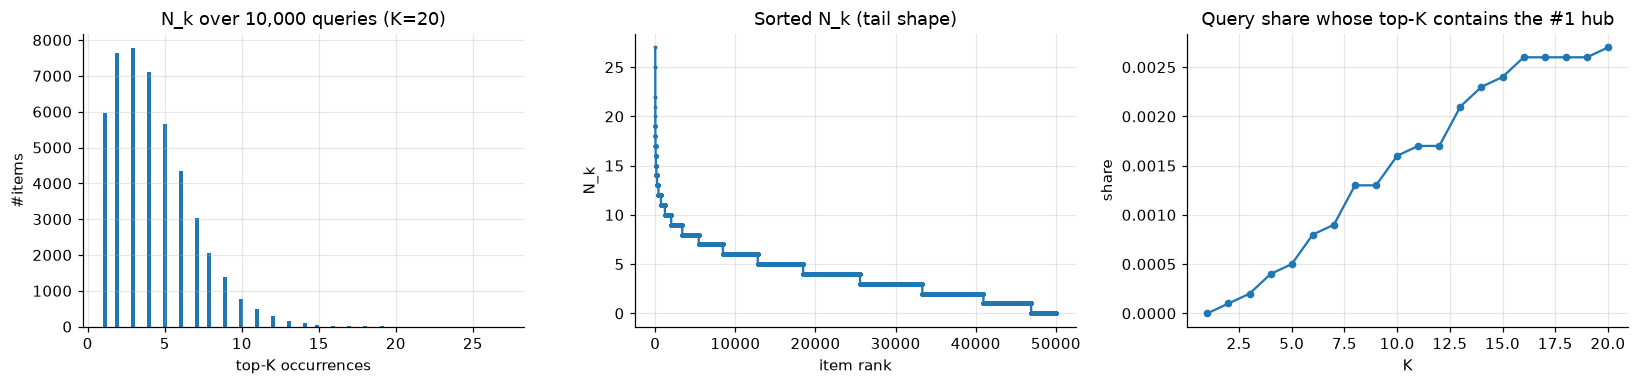

Mean cosine to the #1 hub (item 3027094): +0.0370  (random-pair mean +0.0843)


In [10]:
# ==========================================
# 5. Hubness: are a few items everybody's neighbour?
# ==========================================
hub_q = RNG.choice(N, size=HUB_QUERIES, replace=False)
hub_q.sort()
hub_sim, hub_nn = topk_within_catalog(norm_embeddings[hub_q], norm_embeddings, k=K_NN, self_idx=hub_q)

n_k = np.bincount(hub_nn.ravel(), minlength=N)
p_k = n_k / n_k.sum()
hub_entropy = float(-(p_k[p_k > 0] * np.log(p_k[p_k > 0])).sum())
gini = float(1.0 - 2.0 * np.sum(np.sort(n_k) * (np.arange(1, N + 1) - 0.5)) / (N * n_k.sum()))
top_hub_share = float(np.sort(n_k)[::-1][:max(1, int(0.01 * N))].sum() / n_k.sum())
never_retrieved = float((n_k == 0).mean())
QUALITY.update(hub_entropy=hub_entropy, hub_gini=gini,
               top1pct_hub_share=top_hub_share, pct_never_retrieved=never_retrieved)

print(f'Queries x K            : {HUB_QUERIES:,} x {K_NN} = {HUB_QUERIES * K_NN:,} neighbour slots over {N:,} items')
print(f'Expected slots per item: {HUB_QUERIES * K_NN / N:.2f}')
print(f'Distinct items retrieved: {int((n_k > 0).sum()):,} / {N:,}')
print(f'Never-retrieved items   : {never_retrieved:.2%}')
print(f'N_k entropy / max       : {hub_entropy:.3f} / {np.log(N):.3f}   (closer to max = more uniform)')
print(f'Gini of N_k             : {gini:.4f}   (0 = uniform, 1 = single hub)')
print(f'Top 1% items hold       : {top_hub_share:.2%} of all neighbour slots   (uniform would be ~1%)')
top_hubs = np.argsort(-n_k)[:10]
print('Top 10 hub item_ids     :', embeddings_df.index.values[top_hubs].tolist())
print('Their N_k               :', n_k[top_hubs].tolist())

top_hub = int(np.argmax(n_k))
share_by_rank = [(hub_nn[:, :r] == top_hub).any(axis=1).mean() for r in range(1, K_NN + 1)]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(n_k[n_k > 0], bins=100)
ax[0].set(title=f'N_k over {HUB_QUERIES:,} queries (K={K_NN})', xlabel='top-K occurrences', ylabel='#items')
ax[1].plot(np.sort(n_k)[::-1], marker='.', ms=3)
ax[1].set(title='Sorted N_k (tail shape)', xlabel='item rank', ylabel='N_k')
ax[2].plot(np.arange(1, K_NN + 1), share_by_rank, marker='o', ms=4)
ax[2].set(title='Query share whose top-K contains the #1 hub', xlabel='K', ylabel='share')
plt.tight_layout()
plt.show()

# How close is everything to the #1 hub? High mean = the hub is both frequent and central,
# which is the worst case for diversity (one item answers every query).
hub_cos = norm_embeddings[hub_q] @ norm_embeddings[top_hub]
print(f'Mean cosine to the #1 hub (item {int(embeddings_df.index.values[top_hub])}): {hub_cos.mean():+.4f}  (random-pair mean {pair_cos.mean():+.4f})')

## 6. Duplicate / collapsed items

Two different `item_id`s mapped (almost) to the same point are ambiguous examples: in InfoNCE each of them is treated as a full negative for the other, which caps the achievable loss and silently inflates the effective negative count. On the retrieval side, near-duplicates steal each other's top-1 slot.

Cosine > 0.99 on distinct IDs is the operational definition here, and sizes of connected components in that graph tell you whether it is pairwise noise or a collapsed block of the catalog. The top-5 neighbours here are **reused** from section 4 (`nn_sim` / `nn_idx`) rather than recomputed.

In [11]:
# ==========================================
# 6. Near-duplicate detection (embedding collisions)
# ==========================================
DUP_THRESH = 0.99
dup_sim, dup_nn = nn_sim[:, :5], nn_idx[:, :5]   # reuse section 4 (K_NN=20 covers 5)

dup_rate = float((dup_sim[:, 0] > DUP_THRESH).mean())
QUALITY['pct_items_with_dup'] = dup_rate
print(f'Queries with a >{DUP_THRESH} neighbour: {int((dup_sim[:, 0] > DUP_THRESH).sum()):,} / {q_idx.size:,} ({dup_rate:.2%})')

susp = np.where(dup_sim[:, 0] > DUP_THRESH)[0]
if susp.size:
    print('Example near-duplicate pairs (query id, neighbour id, cosine):')
    for r in susp[:5]:
        print('   ', int(q_idx[r]), int(dup_nn[r, 0]), f'{dup_sim[r, 0]:.5f}')
else:
    print('No near-duplicate pairs found in the sampled queries.')

# Union-find over the duplicate graph -> component sizes (query subsample only).
class _DSU:
    def __init__(self, n):
        self.parent = np.arange(n)
    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[rb] = ra

dsu = _DSU(N)
edges = 0
for r in range(q_idx.size):
    for j in range(5):
        if dup_sim[r, j] > DUP_THRESH:
            dsu.union(int(q_idx[r]), int(dup_nn[r, j]))
            edges += 1
comp = pd.Series([dsu.find(i) for i in range(N)]).value_counts()
print(f'Duplicate-graph edges (>{DUP_THRESH}): {edges:,}; largest component: {int(comp.iloc[0])} item(s)')
print('Component size distribution:', comp.value_counts().head(10).to_dict())

# Tail of the random-pair distribution: if p99.9 is near 1.0 a chunk of the catalog is one point.
qs = np.percentile(pair_cos, [90, 99, 99.9, 100.0])
print('Random-pair cosine quantiles p90/p99/p99.9/max: %.3f / %.3f / %.3f / %.3f' % tuple(qs))
QUALITY['pair_cos_p99_9'] = float(qs[2])
print('Reading: p99.9 << 1 indicates the bulk of the catalog is not collapsed; only the tail matters for duplicates.')

Queries with a >0.99 neighbour: 118 / 20,000 (0.59%)
Example near-duplicate pairs (query id, neighbour id, cosine):
    198 17958 0.99051
    274 19841 0.99544
    1299 25969 0.99133
    1545 15774 0.99197
    1573 8849 0.99209
Duplicate-graph edges (>0.99): 128; largest component: 7 item(s)
Component size distribution: {1: 49799, 2: 91, 3: 4, 7: 1}
Random-pair cosine quantiles p90/p99/p99.9/max: 0.401 / 0.664 / 0.823 / 0.983
Reading: p99.9 << 1 indicates the bulk of the catalog is not collapsed; only the tail matters for duplicates.


## 7. Optional - does the 256-d embedding retain the raw multimodal signal?

`ItemDNN` gets `sem` = `mm_emb` (1024-d, zero-filled when `has_mm_emb` is False), the `has_mm` flag, and 13 categorical embeddings. Two questions worth answering:

1. **Signal retention**: is the learned vector a mostly-isometric summary of `mm_emb`? Tested with a held-out linear probe (fit `W` on the first half, score mean cosine on the second half) plus linear CKA. Low retention is not automatically bad - categoricals may carry the signal - but very low retention means the ItemDNN is essentially re-encoding IDs/categories rather than content.
2. **Zero-modality collapse**: items without `mm_emb` all enter `sem_proj` with the same zero vector, so they can only differ through categoricals. If they pile into one region, they are effectively one item to the retriever.

Skipped automatically if `canonical_items.parquet` (the file passed to `--items_path`) is not present.

In [ ]:
# ==========================================
# 7. Optional: signal retention vs raw mm_emb
# ==========================================
ITEMS_PATH = './canonical_items.parquet'   # set to the --items_path used for training

if not os.path.exists(ITEMS_PATH):
    print(f'Skipped: {ITEMS_PATH} not found. Set ITEMS_PATH to the items parquet passed as --items_path.')
else:
    import pyarrow.parquet as pq
    schema_names = pq.read_schema(ITEMS_PATH).names
    want = [c for c in ['item_id', 'mm_emb', 'has_mm_emb'] if c in schema_names]
    print(f'Columns available in {ITEMS_PATH}: {want}')
    items = pq.read_table(ITEMS_PATH, columns=want).to_pandas()
    items['item_id'] = items['item_id'].astype('int64')
    items = items.set_index('item_id').reindex(embeddings_df.index.astype('int64'))

    if 'mm_emb' not in want:
        print('Skipped: no mm_emb column found.')
    else:
        rows, dim_mm = [], 1
        for v in items['mm_emb'].values:
            r = np.asarray(v, dtype=np.float32).reshape(-1) if v is not None else np.zeros(1, np.float32)
            rows.append(r)
            dim_mm = max(dim_mm, r.size)
        mm = np.vstack([r if r.size == dim_mm else
                        np.concatenate([r, np.zeros(dim_mm - r.size, np.float32)]) for r in rows])
        finite = np.isfinite(mm).all(axis=1)
        nonzero = np.abs(mm).sum(axis=1) > 0
        has_mm = items['has_mm_emb'].fillna(False).to_numpy(dtype=bool) if 'has_mm_emb' in want else (finite & nonzero)
        has_mm = has_mm & finite
        print(f'mm_emb width {dim_mm}; usable rows {finite.sum():,}/{len(mm):,}; has_mm True {has_mm.sum():,} ({has_mm.mean():.1%})')
        QUALITY['pct_items_with_mm'] = float(has_mm.mean())

        sub = np.where(has_mm)[0]
        if sub.size >= 2000:
            sub = RNG.choice(sub, size=min(sub.size, 20_000), replace=False)
            S_mm, E = l2(mm[sub]), norm_embeddings[sub]
            half = sub.size // 2
            W = np.linalg.lstsq(S_mm[:half], E[:half], rcond=None)[0]      # 1024 x 256
            pred = l2(S_mm[half:] @ W)
            probe_cos = np.einsum('ij,ij->i', pred, E[half:])
            cka = linear_cka(S_mm[:half], E[:half])
            QUALITY.update(mm_emb_probe_cos=float(probe_cos.mean()), mm_emb_linear_cka=float(cka))
            print(f'Held-out linear probe mm_emb -> embedding: mean cosine {probe_cos.mean():.4f}  ' +
                  f'p10 {np.percentile(probe_cos, 10):.4f}')
            print(f'Linear CKA(mm_emb, embedding): {cka:.4f}   (0 = unrelated spaces, 1 = identical)')
            print('Interpretation: high probe cosine means the item vector is a compact faithful copy of mm_emb;')
            print('low values mean the categorical/ID path dominates the representation.')
        else:
            print('Skipped probe: fewer than 2000 sampled items carry mm_emb.')

        if has_mm.any() and (~has_mm).any():
            with_mm = norm_embeddings[has_mm]
            without_mm = norm_embeddings[~has_mm]
            print(f'cos to global mean dir: has_mm=1 {float((with_mm @ mean_dir).mean()):+.3f} (n={has_mm.sum():,}) | ' +
                  f'has_mm=0 {float((without_mm @ mean_dir).mean()):+.3f} (n={(~has_mm).sum():,})')
            a = with_mm[:2000] if with_mm.shape[0] > 1 else with_mm
            b = without_mm[:2000] if without_mm.shape[0] > 1 else without_mm
            if a.shape[0] > 1 and b.shape[0] > 1:
                off = ~np.eye(a.shape[0], dtype=bool)
                within_a = float((a @ a.T)[off].mean())
                cross = float((a @ b.T).mean())
                QUALITY.update(mm_within_cos=within_a, mm_cross_cos=cross, mm_group_gap=within_a - cross)
                print(f'Mean cosine within has_mm=1: {within_a:+.3f} | across has_mm groups: {cross:+.3f} | gap {within_a - cross:+.3f}')
                print('A large positive gap means the zero-modality items form their own cluster (they cannot share content with mm items).')
            else:
                print('Skipped cross-group check: one of the groups is empty in the sample.')
        else:
            print('Skipped cross-group check: all sampled items share the same has_mm value.')

## 8. Optional - does the geometry agree with observed behaviour?

Sections 1-6 measure geometry against itself. This section tests it against data: consecutive `history_items` in the preprocessed training samples are real user transitions, so `cos(adjacent pair)` should exceed a control built from the same values.

Control note: shuffling one side permutes the partner, so the control keeps the same second-item marginals but destroys the pairing. The gap therefore measures *pairing* signal, not marginal popularity, which is exactly what we want.

Skipped automatically if the training-samples parquet (`--train_samples_path`) is absent. Only `history_items` is read, and only the first `MAX_SEQ_ROWS` rows.

In [ ]:
# ==========================================
# 8. Optional: adjacent-history pairs should be closer than shuffled pairs
# ==========================================
TRAIN_SAMPLES_PATH = './train_samples.parquet'   # the --train_samples_path used for training
MAX_SEQ_ROWS = 20_000

if not os.path.exists(TRAIN_SAMPLES_PATH):
    print(f'Skipped: {TRAIN_SAMPLES_PATH} not found. Set it to the preprocessed train table (--train_samples_path).')
else:
    import pyarrow.parquet as pq
    tbl = pq.read_table(TRAIN_SAMPLES_PATH, columns=['history_items']).slice(0, MAX_SEQ_ROWS).to_pandas()
    id_to_row = pd.Series(np.arange(N, dtype=np.int64), index=embeddings_df.index.astype('int64'))

    left_parts, right_parts = [], []
    for seq in tbl['history_items']:
        s = np.asarray(seq, dtype=np.int64)
        if s.size < 2:
            continue
        same = s[1:] == s[:-1]
        left_parts.append(s[:-1][~same])
        right_parts.append(s[1:][~same])

    if left_parts:
        pos_l = np.concatenate(left_parts).astype(np.int64)
        pos_r = np.concatenate(right_parts).astype(np.int64)
        li = id_to_row.reindex(pos_l).to_numpy()
        ri = id_to_row.reindex(pos_r).to_numpy()
        ok = ~(pd.isna(li) | pd.isna(ri))
        li, ri = li[ok].astype(np.int64), ri[ok].astype(np.int64)
        ok2 = li != ri
        li, ri = li[ok2], ri[ok2]
        print(f'Adjacent-history pairs usable from {len(tbl):,} sampled sequences: {li.size:,}')

        if li.size > 500_000:
            sel = RNG.choice(li.size, size=500_000, replace=False)
            li, ri = li[sel], ri[sel]
            print(f'Subsampled to {li.size:,} pairs for speed.')

        if li.size:
            pos_sim = np.einsum('ij,ij->i', norm_embeddings[li], norm_embeddings[ri])
            ctrl_sim = np.einsum('ij,ij->i', norm_embeddings[li], norm_embeddings[RNG.permutation(ri)])
            gap = float(pos_sim.mean() - ctrl_sim.mean())
            QUALITY.update(cooccur_pos_cos=float(pos_sim.mean()),
                           cooccur_ctrl_cos=float(ctrl_sim.mean()), cooccur_gap=gap)
            print(f'cos(observed adjacent pair) : {pos_sim.mean():+.4f}')
            print(f'cos(shuffled control)       : {ctrl_sim.mean():+.4f}')
            print(f'Pairing gap                 : {gap:+.4f}   (0 = the embedding ignores real co-occurrence)')
            print(f'Random-pair baseline for reference: {pair_cos.mean():+.4f}')

            fig, ax = plt.subplots(figsize=(8, 3.4))
            ax.hist(pos_sim, bins=100, alpha=0.8, density=True, label='observed adjacent pair')
            ax.hist(ctrl_sim, bins=100, alpha=0.6, density=True, label='shuffled control')
            ax.axvline(pair_cos.mean(), color='k', ls=':', label='random-pair mean')
            ax.set(title='Adjacent-history cosine vs control', xlabel='cosine', ylabel='density')
            ax.legend()
            plt.tight_layout()
            plt.show()
        else:
            print('No usable pairs after mapping to the sampled item_ids.')
    else:
        print('No sequences with at least two distinct items in the sampled rows.')

## 9. Optional - does `item_id` ordering leak into the geometry?

If `item_id`s are assigned by creation time (common for video/article catalogs), a leading principal component that correlates with `item_id` means the embedding is largely encoding **item age** rather than content. That is a real quality defect: it makes "similar items" mostly "items from the same era", and it interacts badly with the `log_q` popularity term.

Checked with Spearman correlation between `item_id` rank and PC1 / PC2. Rule of thumb: `|rho| > 0.3` on a leading component is suspicious (Spearman is used so a monotone but non-linear drift still shows up).

In [ ]:
# ==========================================
# 9. Does item_id ordering leak into the geometry?
# ==========================================
score = V[:2] @ norm_embeddings.T          # (2, N) projections on PC1 and PC2
id_rank = pd.Series(embeddings_df.index.values).rank().to_numpy()
sp1 = float(pd.Series(score[0]).corr(pd.Series(id_rank), method='spearman'))
sp2 = float(pd.Series(score[1]).corr(pd.Series(id_rank), method='spearman'))
QUALITY.update(pc1_itemid_spearman=sp1, abs_pc1_itemid_spearman=abs(sp1))

print(f'Spearman(item_id rank, PC1) = {sp1:+.3f}')
print(f'Spearman(item_id rank, PC2) = {sp2:+.3f}')
print('Reference: |rho| > 0.3 on a leading component means item_id order is a major axis of the space.')
print(f'PC1 explains {evr[0] / evr.sum():.1%} of total variance.')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(id_rank, score[0], s=1, alpha=0.15)
ax[0].set(title='PC1 vs item_id rank', xlabel='item_id rank', ylabel='PC1 projection')
ax[1].scatter(score[0], score[1], s=1, alpha=0.15)
ax[1].set(title='PC1 vs PC2 (all items)', xlabel='PC1', ylabel='PC2')
plt.tight_layout()
plt.show()

# Time-ordered slices: if early and late item_ids overlap fully, there is no temporal drift.
q = np.quantile(id_rank, [0.25, 0.75])
early = norm_embeddings[id_rank <= q[0]][:3000]
late = norm_embeddings[id_rank > q[1]][:3000]
if early.shape[0] > 1 and late.shape[0] > 1:
    cross = float((early @ late.T).mean())
    within = float((early @ early.T)[~np.eye(early.shape[0], dtype=bool)].mean())
    QUALITY.update(itemid_early_late_cos=cross)
    print(f'Mean cosine within the earliest quartile: {within:+.4f}')
    print(f'Mean cosine earliest vs latest quartile  : {cross:+.4f}')
    print('A large negative split here would confirm strong era separation - and a disambiguation problem for the retriever.')

## 10. Optional - cluster structure (needs scikit-learn)

A healthy item space has *some* group structure (genre/topic/style clusters) rather than one uniform blob. Two cheap views: k-means in the leading PCA subspace, and a 2-D PCA scatter coloured by cluster label.

- **Silhouette** on a 10k sample: ~0 means no cluster structure at all (continuous space is fine for retrieval, but suspicious for item content), 0.1-0.3 is a reasonable weak-to-moderate structure, >0.5 usually means near-duplicates are forming.
- **Cluster size balance**: one giant cluster plus many tiny ones is a hint of an unstructured core, which interacts with the hubness numbers in section 5.

Skipped automatically if scikit-learn is not installed - nothing is installed here on purpose.

In [ ]:
# ==========================================
# 10. Optional: cluster structure (sklearn)
# ==========================================
try:
    from sklearn.cluster import MiniBatchKMeans
    from sklearn.metrics import silhouette_score
    HAS_SKLEARN = True
except ImportError:
    HAS_SKLEARN = False

if not HAS_SKLEARN:
    print('scikit-learn is not installed; skipping clustering (nothing was installed by this notebook).')
else:
    K_CLUSTERS = 32
    N_PCS = min(32, V.shape[0])
    Z = norm_embeddings @ V[:N_PCS].T        # low-rank PCA space: cheap for k-means
    km = MiniBatchKMeans(n_clusters=K_CLUSTERS, random_state=RANDOM_SEED, n_init=10, batch_size=4096).fit(Z)
    lab = km.labels_
    sil_idx = RNG.choice(N, size=min(N, 10_000), replace=False)
    sil = float(silhouette_score(Z[sil_idx], lab[sil_idx], metric='euclidean'))
    sizes = np.bincount(lab, minlength=K_CLUSTERS)
    QUALITY.update(kmeans_silhouette=sil, kmeans_max_cluster_share=float(sizes.max() / sizes.sum()))

    print(f'MiniBatchKMeans K={K_CLUSTERS} on {N_PCS}-d PCA space')
    print(f'Silhouette (10k sample)      : {sil:.4f}')
    print(f'Cluster sizes min/median/max : {sizes.min():,} / {int(np.median(sizes)):,} / {sizes.max():,}')
    print(f'Largest cluster share        : {sizes.max() / sizes.sum():.1%}')

    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    ax[0].bar(np.arange(K_CLUSTERS), np.sort(sizes)[::-1])
    ax[0].set(title='Cluster sizes (sorted)', xlabel='cluster', ylabel='#items')
    ax[1].scatter(score[0][sil_idx], score[1][sil_idx], c=lab[sil_idx], s=3, cmap='tab20')
    ax[1].set(title=f'PCA-2D coloured by cluster (silhouette {sil:.3f})', xlabel='PC1', ylabel='PC2')
    plt.tight_layout()
    plt.show()

    # Sanity: do clusters line up with the item_id axis (i.e. are they time buckets)?
    ct = pd.crosstab(lab, np.digitize(id_rank, np.quantile(id_rank, [0.25, 0.5, 0.75])))
    print('Cluster x item_id-quartile contingency (first 8 rows):')
    print(ct.head(8))

## 11. Scorecard

Every headline number in one table, with heuristic thresholds for a 256-d L2-normalized contrastive item space. Treat the verdicts as triage, not verdict-by-law: read the plots for the sections marked `WATCH`, and cross-check against the training curve (`val/recall@10`, `val/mrr`, `val/cosine_gap`) before changing the model.

In [ ]:
# ==========================================
# 11. Scorecard
# ==========================================
def verdict(value, kind, thr):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return 'n/a'
    if kind == 'lt':
        return 'OK' if value < thr else 'WATCH'
    if kind == 'gt':
        return 'OK' if value > thr else 'WATCH'
    if kind == 'abs_lt':
        return 'OK' if abs(value) < thr else 'WATCH'
    return 'n/a'

CHECKS = [
    ('unit_norm_deviation_p99', 'norm_dev_p99',              'lt',     1e-3, 'max |norm|-1 at p99; export/normalization bug check'),
    ('dead_dimensions',         'dead_dims',                 'lt',     1,    'output dims with std < 1e-3'),
    ('cone_collapse',           'mean_cos_to_centroid',      'lt',     0.50, 'mean cos to global mean direction'),
    ('effective_rank',          'eff_rank',                  'gt',     32,   'exp-entropy effective rank out of 256'),
    ('participation_ratio',     'part_ratio',                'gt',     16,   'variance-weighted rank'),
    ('anisotropy',              'random_pair_cos_mean',      'abs_lt', 0.30, 'mean cosine of random pairs (want ~0)'),
    ('uniformity',              'uniformity',                'lt',     -2.0, 'log E[exp(-2 d^2)]; more negative = better spread'),
    ('retrieval_margin',        'nn1_rand_gap',              'gt',     0.30, 'cos(1-NN) - cos(random item)'),
    ('weak_1nn_p10',            'nn1_cos_p10',               'gt',     0.30, 'p10 of 1-NN cosine; low = many isolated items'),
    ('duplicate_rate',          'pct_items_with_dup',        'lt',     0.01, 'share of items with a >0.99 cosine twin'),
    ('hubness_gini',            'hub_gini',                  'lt',     0.50, 'inequality of top-K occurrence counts'),
    ('never_retrieved',         'pct_never_retrieved',       'lt',     0.20, 'items absent from every top-K list'),
    ('hub_slot_concentration',  'top1pct_hub_share',         'lt',     0.10, 'neighbour slots held by the top 1% of items'),
    ('mm_emb_probe_cosine',     'mm_emb_probe_cos',          'gt',     0.50, 'optional: held-out linear recovery of mm_emb'),
    ('cooccurrence_gap',        'cooccur_gap',               'gt',     0.05, 'optional: observed transitions vs shuffled control'),
    ('itemid_leakage',          'abs_pc1_itemid_spearman',   'lt',     0.30, 'optional: |Spearman(PC1, item_id rank)|'),
    ('cluster_silhouette',      'kmeans_silhouette',         'gt',     0.05, 'optional: sklearn silhouette, K=32'),
]

rows = []
for name, key, kind, thr, note in CHECKS:
    value = QUALITY.get(key)
    rows.append({'check': name, 'value': value, 'rule': f'{kind} {thr}',
                 'verdict': verdict(value, kind, thr), 'meaning': note})

scorecard = pd.DataFrame(rows)
watched = int((scorecard['verdict'] == 'WATCH').sum())
skipped = scorecard.loc[scorecard['verdict'] == 'n/a', 'check'].tolist()
print(scorecard.assign(value=scorecard['value'].map(lambda v: 'n/a' if v is None else f'{v:.4g}')).to_string(index=False))
print(f'\nChecks: {len(CHECKS)}  WATCH: {watched}  skipped (optional section not run): {len(skipped)}')
if skipped:
    print('Skipped checks:', skipped)
print('Metrics captured in QUALITY:', len(QUALITY))

scorecard

## 12. How to act on the results

| Symptom found here | Likely cause in `train_item_embedding_cli.py` | Lever |
| --- | --- | --- |
| High anisotropy / crowding, uniformity > ~-1 | `temperature=0.05` too low, or too few effective negatives | raise `--temperature`, add `--cross_gpu_negatives`, larger `--batch_size` |
| Low effective rank / dead dims | dimensional collapse; `output_dim=256` over-parameterized for the signal | lower `--output_dim`, add projection head, check `--dropout` |
| Many near-duplicates | duplicate catalog rows or coarse categoricals dominating `item_dnn_hidden_dims` | dedupe items, increase `--cat_emb_dim`, verify `has_mm_emb` coverage |
| Few isolated items (low p10 1-NN) | items with no `mm_emb` and rare categoricals fall back to near-zero `sem` | raise `--raw_emb_dim` coverage, add ID/attribute features, backfill `mm_emb` |
| Strong item_id/PC1 correlation | time-ordered IDs leaking through sparse categoricals | add time-decay features or split by time, check `--log_q_weight` |
| Weak co-occurrence gap | the item space is not aligned with behaviour - the HSTU side may be carrying the task | inspect `val/recall@10` vs `val/cosine_gap` in TensorBoard, consider a stronger item-side signal |

**Next diagnostics that need the model, not the export:** load `stage1_rec_model.pt`, rebuild `ItemDNN` with the stored `cardinalities` / `cat_cols`, and recompute `compute_ranking_metrics` on the val loader to get `recall@k`, `mrr`, `cosine_gap` for the exact checkpoint behind this export. That plus this scorecard is the full picture.